[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/02-data-science/08_statistics.ipynb)

*Python for Data Science · Notebook 8 of 8*

# Statistics for Data Analysis

Describe and compare data: centre, spread, percentiles, outliers, correlation, simple regression and basic probability.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Statistics is how you stay honest with a small sample: it asks whether what you saw could just be luck.

**What interviewers really test here:** Mean vs median, standard deviation, confidence intervals, p-values and correlation vs causation.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Centre: mean, median, mode *(Basics)*
- [ ] 2. Spread: range, IQR, variance, standard deviation *(Basics)*
- [ ] 3. Variance and standard deviation by hand *(Basics)*
- [ ] 4. Standardising and outliers *(Core)*
- [ ] 5. Relationships: correlation and covariance *(Core)*
- [ ] 6. Correlation by hand, and its traps *(Core)*
- [ ] 7. Samples, standard error and confidence intervals *(Core)*
- [ ] 8. Fitting a line: simple linear regression *(Advanced)*
- [ ] 9. Probability and confidence intervals *(Advanced)*
- [ ] 10. A hypothesis test by hand: an A/B test *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Descriptive vs inferential statistics

**Descriptive statistics** summarise the data you have: centre, spread, shape, relationships. **Inferential statistics** use a sample to draw conclusions about a larger **population**, with a measure of uncertainty (confidence intervals, hypothesis tests). A **parameter** describes the population (μ, σ); a **statistic** is computed from the sample (x̄, s) and estimates it.

### Types of variables

| Type | Examples | Typical summaries |
| --- | --- | --- |
| Nominal (categorical) | city, colour | counts, mode, proportions |
| Ordinal | rating 1–5, size S/M/L | median, percentiles |
| Discrete numeric | number of children | mean, median, std |
| Continuous numeric | height, price | mean, median, std, histogram |

### Formulas

| Measure | Formula | NumPy / pandas |
| --- | --- | --- |
| Mean | x̄ = Σx / n | `a.mean()` |
| Population variance | σ² = Σ(x − μ)² / n | `a.var()` |
| Sample variance | s² = Σ(x − x̄)² / (n − 1) | `a.var(ddof=1)`, `s.var()` |
| z-score | (x − x̄) / s | `(a - a.mean()) / a.std()` |
| Covariance | Σ(x − x̄)(y − ȳ) / (n − 1) | `np.cov(x, y)[0, 1]` |
| Pearson r | cov(x, y) / (sₓ s\_y) | `np.corrcoef(x, y)[0, 1]` |
| Slope (least squares) | Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² | `np.polyfit(x, y, 1)` |
| R² | 1 − SS\_res / SS\_tot | — |
| Standard error | s / √n | `s.sem()` |



Dividing by **n − 1** (Bessel's correction) makes the sample variance an unbiased estimate of the population variance, because deviations are measured from x̄, which is itself fitted to the sample.

### Shape of a distribution

- **Symmetric** (e.g. normal): mean ≈ median. About 68% of values lie within 1σ, 95% within 2σ, 99.7% within 3σ (the empirical rule).
- **Right-skewed** (income, waiting times): long tail to the right, mean &gt; median, skewness &gt; 0.
- **Left-skewed** (exam scores near a ceiling): mean &lt; median, skewness &lt; 0.
- **Bimodal**: two peaks, often a sign of two mixed groups.

### Common probability distributions

| Distribution | Models | Parameters |
| --- | --- | --- |
| Bernoulli | one yes/no trial | p |
| Binomial | number of successes in n trials | n, p |
| Poisson | count of events in an interval | λ |
| Uniform | every value equally likely | a, b |
| Normal | sums/averages of many effects | μ, σ |
| Exponential | waiting time between events | λ |



The **Central Limit Theorem** says the mean of a large enough sample is approximately normally distributed whatever the original shape — which is why mean ± 1.96·SE works as a 95% interval.

### Hypothesis testing in one paragraph

State a **null hypothesis** H₀ (e.g. "both groups have the same mean"). Compute a test statistic from the data and its **p-value**: the probability of a result at least this extreme if H₀ were true. If p &lt; α (often 0.05), reject H₀. Common tests: t-test (compare means), chi-square (categorical association), ANOVA (several means). In Python these live in `scipy.stats` (`ttest_ind`, `chi2_contingency`, `pearsonr`).

---
# Part 2: Lessons, step by step

## Lesson 1: Centre: mean, median, mode

*Level: Basics*

A **statistic** is a single number that summarises many values. The first question is always *"what is a typical value?"*



| Measure | How | Use when |
| --- | --- | --- |
| **Mean** | sum ÷ count | data is roughly symmetric |
| **Median** | middle value after sorting | there are outliers or skew (salaries, house prices) |
| **Mode** | most frequent value | categories ("most common city") |



```python
a = np.array(marks)
a.mean(), np.median(a)
pd.Series(marks).mode()     # can return several values
```



One huge value drags the mean but barely moves the median — compare them to spot skew.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

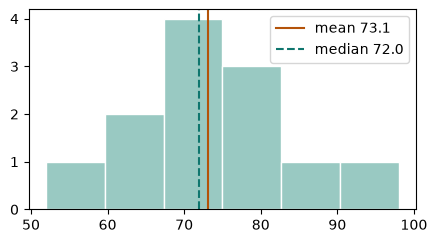

In [2]:
MARKS = [52, 61, 64, 68, 70, 71, 73, 75, 78, 82, 85, 98]


def centre_demo():
    a = np.array(MARKS)
    mean = a.mean()
    median = np.median(a)
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.hist(a, bins=6, color="#99c9c2", edgecolor="white")
    ax.axvline(mean, color="#b45309", label=f"mean {mean:.1f}")
    ax.axvline(median, color="#0f766e", linestyle="--", label=f"median {median:.1f}")
    ax.legend()


centre_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q5](#q5), [Q6](#q6). Try one now, or carry on and do them in Part 3.

## Lesson 2: Spread: range, IQR, variance, standard deviation

*Level: Basics*

Two classes can share a mean of 70 yet one has everyone between 65 and 75 and the other ranges from 30 to 100. **Spread** tells them apart.




- **Range** = max − min (one outlier ruins it).
- **Quartiles**: Q1 (25th percentile), Q2 = median, Q3 (75th). **IQR** = Q3 − Q1 — the middle half of the data.
- **Variance** = average squared distance from the mean. **Standard deviation** = √variance, back in the original units.



```python
np.percentile(a, [25, 50, 75])
a.std()           # NumPy: population (divide by n)
a.std(ddof=1)     # sample (divide by n − 1) — what pandas .std() uses
```



Use **n − 1** (sample) when your data is a sample of a bigger population — the usual case.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

/var/folders/85/fjydk44j4x3bx7vvx_k5s0qc0000gn/T/ipykernel_6830/3866324465.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(a, vert=False)


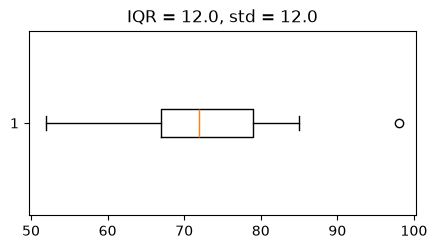

In [3]:
MARKS = [52, 61, 64, 68, 70, 71, 73, 75, 78, 82, 85, 98]


def spread_demo():
    a = np.array(MARKS, dtype=float)
    q1, q3 = np.percentile(a, [25, 75])
    iqr = q3 - q1
    std = a.std(ddof=1)
    fig, ax = plt.subplots(figsize=(5, 2.4))
    ax.boxplot(a, vert=False)
    ax.set_title(f"IQR = {iqr:.1f}, std = {std:.1f}")


spread_demo()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q11](#q11), [Q7](#q7), [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 3: Variance and standard deviation by hand

*Level: Basics*

Values: 2, 4, 4, 4, 5, 5, 7, 9. The mean is 40 / 8 = 5.



<table><tr><th>x</th><th>x − mean</th><th>(x − mean)²</th></tr> <tr><td>2</td><td>−3</td><td>9</td></tr><tr><td>4</td><td>−1</td><td>1</td></tr><tr><td>4</td><td>−1</td><td>1</td></tr><tr><td>4</td><td>−1</td><td>1</td></tr> <tr><td>5</td><td>0</td><td>0</td></tr><tr><td>5</td><td>0</td><td>0</td></tr><tr><td>7</td><td>2</td><td>4</td></tr><tr><td>9</td><td>4</td><td>16</td></tr> <tr><th colspan="2">Total</th><th>32</th></tr></table>



|   | Variance | Standard deviation |
| --- | --- | --- |
| Population (÷ n) | 32 / 8 = 4 | 2 |
| Sample (÷ (n − 1)) | 32 / 7 = 4.571 | 2.138 |



#### Why square the differences?



Plain differences always add up to 0, because positives cancel negatives. Squaring makes them all count. Taking the root at the end returns to the original units.



#### Why n − 1?



We measured distances from the sample's own mean, which sits closer to the data than the true mean does. So the sum is a little too small, and dividing by n − 1 corrects it.



**Beware the defaults:** `np.std` divides by n, and pandas `.std()` divides by n − 1.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def variance_by_hand():
    x = np.array([2, 4, 4, 4, 5, 5, 7, 9], dtype=float)
    differences = x - x.mean()
    add_to_zero = differences.sum()
    squares = differences ** 2
    population_variance = squares.sum() / len(x)
    sample_variance = squares.sum() / (len(x) - 1)
    numpy_default = x.std()
    pandas_default = pd.Series(x).std()


variance_by_hand()

**✏️ Your turn:** you now have what you need for [Q11](#q11), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 4: Standardising and outliers

*Level: Core*

A **z-score** says how many standard deviations a value is from the mean: `z = (x − mean) / std`. It lets you compare a 72 in Maths with an 80 in English.



Two common outlier rules:



| Rule | Outlier if | Good for |
| --- | --- | --- |
| z-score | \|z\| &gt; 2 or 3 | roughly bell-shaped data |
| IQR (Tukey) | below Q1 − 1.5·IQR or above Q3 + 1.5·IQR | any shape — what box plots use |



**Skewness** measures lopsidedness: positive means a long right tail (mean &gt; median).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [5]:
MARKS = [52, 61, 64, 68, 70, 71, 73, 75, 78, 82, 85, 98]


def z_demo():
    a = np.array(MARKS, dtype=float)
    z = (a - a.mean()) / a.std()
    flagged = a[np.abs(z) > 1.5]
    q1, q3 = np.percentile(a, [25, 75])
    fence_hi = q3 + 1.5 * (q3 - q1)


z_demo()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 5: Relationships: correlation and covariance

*Level: Core*

Do two numbers move together? **Covariance** is positive if they rise together, negative if one falls as the other rises — but its size depends on units. **Pearson's r** rescales it to −1 … +1.



| r | Meaning |
| --- | --- |
| +1 | perfect straight line up |
| ≈ 0 | no straight-line relationship |
| −1 | perfect straight line down |



```python
np.corrcoef(x, y)[0, 1]
df.corr(numeric_only=True)              # whole matrix
s.rank().corr(t.rank())                 # Spearman: monotonic, robust to outliers
```



**Correlation is not causation**: ice-cream sales and drownings correlate because both rise in summer.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

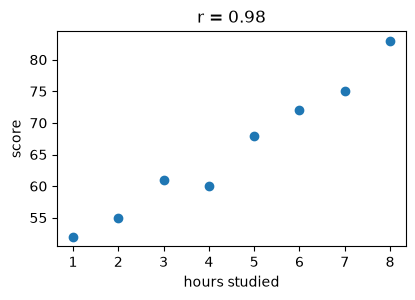

In [6]:
def corr_demo():
    hours = np.array([1, 2, 3, 4, 5, 6, 7, 8])
    score = np.array([52, 55, 61, 60, 68, 72, 75, 83])
    r = np.corrcoef(hours, score)[0, 1]
    fig, ax = plt.subplots(figsize=(4.5, 2.8))
    ax.scatter(hours, score)
    ax.set_xlabel("hours studied")
    ax.set_ylabel("score")
    ax.set_title(f"r = {r:.2f}")


corr_demo()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q4](#q4), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 6: Correlation by hand, and its traps

*Level: Core*

x = 1, 2, 3, 4, 5 and y = 2, 4, 5, 4, 5. The means are 3 and 4.



| dx | dy | dx·dy | dx² | dy² |
| --- | --- | --- | --- | --- |
| −2 | −2 | 4 | 4 | 4 |
| −1 | 0 | 0 | 1 | 0 |
| 0 | 1 | 0 | 0 | 1 |
| 1 | 0 | 0 | 1 | 0 |
| 2 | 1 | 2 | 4 | 1 |
| Total |   | 6 | 10 | 6 |



r = 6 / √(10 × 6) = **0.775**. When x is above average, y usually is too, so the products are mostly positive.



#### Three traps



1. **Curves:** y = x² on x = −2 … 2 gives **r = 0**, although y depends entirely on x.
2. **Outliers:** five points with r = −0.693 become r = **+0.963** when one extreme point is added. Try Spearman, and always plot.
3. **Hidden causes:** ice-cream sales and drownings rise together because of summer.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

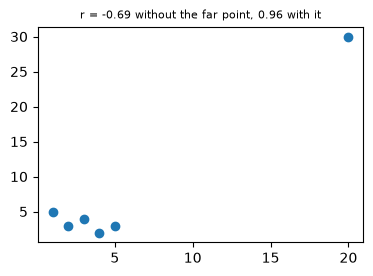

In [7]:
def correlation_traps():
    x = np.arange(-2, 3)
    curve_r = np.corrcoef(x, x ** 2)[0, 1]
    a = np.array([1, 2, 3, 4, 5, 20], dtype=float)
    b = np.array([5, 3, 4, 2, 3, 30], dtype=float)
    without_outlier = np.corrcoef(a[:-1], b[:-1])[0, 1]
    with_outlier = np.corrcoef(a, b)[0, 1]
    spearman = pd.Series(a).rank().corr(pd.Series(b).rank())
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    ax.scatter(a, b)
    ax.set_title(f"r = {without_outlier:.2f} without the far point, {with_outlier:.2f} with it", fontsize=8)


correlation_traps()

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q4](#q4), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 7: Samples, standard error and confidence intervals

*Level: Core*

A sample's mean changes from sample to sample. The **standard error** (SE) measures by how much: SE = s / √n.



#### Worked example



25 students score a mean of 70, with s = 10.



1. SE = 10 / √25 = 2.
2. 95% interval = 70 ± 1.96 × 2 = **66.08 to 73.92**.



To **halve** the SE you need **four times** the data, as √n is on the bottom.



#### Saying it correctly



- **Right:** if we repeated this many times, about 95% of such intervals would contain the true mean.
- **Wrong:** "95% of students score in this range." That describes the mean, not individuals. For individuals, you'd use s, not SE.



The demo draws 1,000 samples from a very skewed population. Their means still form a bell shape that narrows as n grows: the central limit theorem at work.



**With small samples** (say under 30), replace 1.96 with a slightly larger value from the t-distribution.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

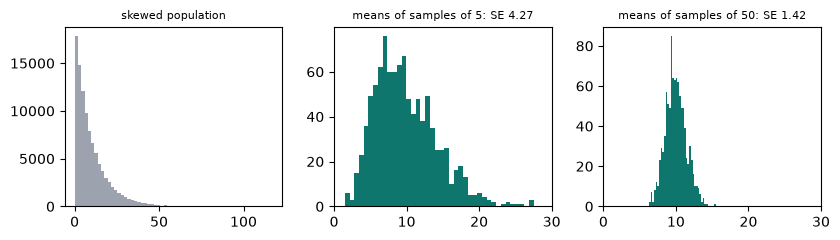

In [8]:
def sampling_means():
    r = np.random.default_rng(0)
    population = r.exponential(10, 100000)
    fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.5))
    axes[0].hist(population, bins=60, color="#9ca3af")
    axes[0].set_title("skewed population", fontsize=8)
    for ax, n in zip(axes[1:], [5, 50]):
        means = r.choice(population, (1000, n)).mean(axis=1)
        ax.hist(means, bins=40, color="#0f766e")
        ax.set_xlim(0, 30)
        ax.set_title(f"means of samples of {n}: SE {means.std():.2f}", fontsize=8)
    fig.tight_layout()


sampling_means()

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 8: Fitting a line: simple linear regression

*Level: Advanced*

Regression goes one step further than correlation: it finds the line `y = slope·x + intercept` that minimises the squared vertical errors (**least squares**).



```python
slope, intercept = np.polyfit(x, y, 1)
pred = slope * x + intercept
r2 = 1 - ((y - pred)**2).sum() / ((y - y.mean())**2).sum()
```




- **slope**: how much y changes when x grows by 1.
- **R²**: share of y's variation the line explains (0 … 1). For one predictor, R² = r².
- Only predict inside the x range you trained on — extrapolation is risky.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

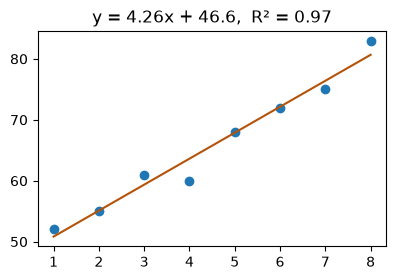

In [9]:
def regression_demo():
    x = np.array([1, 2, 3, 4, 5, 6, 7, 8])
    y = np.array([52, 55, 61, 60, 68, 72, 75, 83])
    slope, intercept = np.polyfit(x, y, 1)
    pred = slope * x + intercept
    r2 = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    fig, ax = plt.subplots(figsize=(4.5, 2.8))
    ax.scatter(x, y)
    ax.plot(x, pred, color="#b45309")
    ax.set_title(f"y = {slope:.2f}x + {intercept:.1f},  R² = {r2:.2f}")


regression_demo()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q8](#q8), [Q16](#q16). Try one now, or carry on and do them in Part 3.

## Lesson 9: Probability and confidence intervals

*Level: Advanced*

**Empirical probability** = favourable cases ÷ all cases in your data: `(a >= 70).mean()`.



The **binomial** formula gives the chance of exactly k successes in n independent tries with chance p: `C(n, k) · pᵏ · (1 − p)ⁿ⁻ᵏ` (`math.comb(n, k)`).



A sample mean is only an estimate. Its **standard error** is `s / √n`, and a rough **95% confidence interval** is `mean ± 1.96 × SE`: if you repeated the sampling many times, about 95% of such intervals would contain the true mean. More data → smaller SE → narrower interval.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

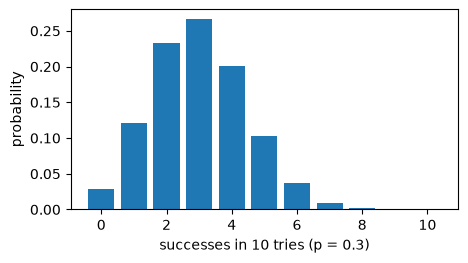

In [10]:
import math


def binomial_demo():
    import math
    n, p = 10, 0.3
    ks = list(range(n + 1))
    probs = [math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in ks]
    fig, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(ks, probs)
    ax.set_xlabel("successes in 10 tries (p = 0.3)")
    ax.set_ylabel("probability")


binomial_demo()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q19](#q19), [Q18](#q18), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 10: A hypothesis test by hand: an A/B test

*Level: Advanced*

Page A: 200 of 2,000 visitors buy (10%). Page B: 250 of 2,000 buy (12.5%). Could that gap just be chance?



#### The steps



1. **Null hypothesis:** both pages have the same true rate.
2. **Pooled rate:** 450 / 4000 = 0.1125.
3. **Standard error of the gap:** √(0.1125 × 0.8875 × (1/2000 + 1/2000)) = 0.00999.
4. **z-score:** (0.125 − 0.10) / 0.00999 = **2.50**.
5. **p-value:** the chance of a gap this large, in either direction, if the null were true = **0.012**.



That's below the usual 0.05, so we reject the null: the gap is unlikely to be chance alone.



#### What it doesn't say



- p isn't the chance that the null is true.
- **Significant isn't the same as important:** with huge data, a tiny useless gap can be significant. Report the size of the effect with an interval.
- **Don't peek and stop early** when the result looks good, and be careful testing many metrics: at 0.05, 1 in 20 tests of nothing looks "significant".



| Error | Meaning |
| --- | --- |
| Type I (false positive) | you claim an effect that isn't there |
| Type II (false negative) | you miss a real effect; more data reduces this |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

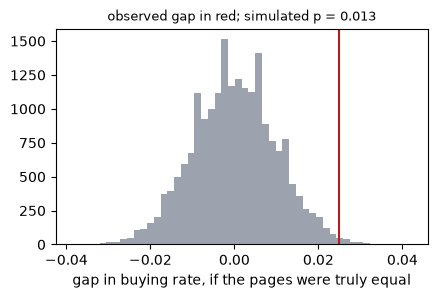

In [11]:
import math


def ab_test():
    a_buy, b_buy, n = 200, 250, 2000
    p_a, p_b = a_buy / n, b_buy / n
    pooled = (a_buy + b_buy) / (2 * n)
    se = (pooled * (1 - pooled) * (2 / n)) ** 0.5
    z = (p_b - p_a) / se
    p_value = 2 * (1 - 0.5 * (1 + math.erf(z / 2 ** 0.5)))
    r = np.random.default_rng(0)
    null_gaps = (r.binomial(n, pooled, 20000) - r.binomial(n, pooled, 20000)) / n
    simulated_p = (np.abs(null_gaps) >= p_b - p_a).mean()
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.hist(null_gaps, bins=50, color="#9ca3af")
    ax.axvline(p_b - p_a, color="#b91c1c")
    ax.set_xlabel("gap in buying rate, if the pages were truly equal")
    ax.set_title(f"observed gap in red; simulated p = {simulated_p:.3f}", fontsize=9)


ab_test()

**✏️ Your turn:** you now have what you need for [Q19](#q19), [Q9](#q9). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Mean, Median and Mode

🟢 Warm-up · *Measures of centre*

Return `(mean, median, mode)`. If several values tie for mode, return the smallest.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `(5.0, 4.5, 4)`
- `values = [1, 3, 3, 6, 7, 8, 9]` → `(5.2857, 6.0, 3)`

In [ ]:
def centre(values):
    """
    Return (mean, median, mode). If several values tie for mode, return the
    smallest.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(centre, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), (5.0, 4.5, 4)),
    (([1, 3, 3, 6, 7, 8, 9],), (5.2857, 6.0, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sum and divide; sort and take the middle; count each value.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.mean`, `np.median` and pandas `Series.mode()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sum and divide; sort and take the middle; count each value.

```python
def centre(values):
    n = len(values)
    mean = sum(values) / n
    s = sorted(values)
    median = s[n // 2] if n % 2 else (s[n // 2 - 1] + s[n // 2]) / 2
    counts = {}
    for v in values:
        counts[v] = counts.get(v, 0) + 1
    best = max(counts.values())
    mode = min(v for v, c in counts.items() if c == best)
    return (mean, float(median), mode)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.mean`, `np.median` and pandas `Series.mode()`.

```python
def centre(values):
    a = np.array(values)
    mode = pd.Series(values).mode().min()
    return (a.mean(), np.median(a), mode)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sum and divide; sort and take the middle; count each value. That costs O(n log n) time and O(n) space."

"I can do better: `np.mean`, `np.median` and pandas `Series.mode()`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/mean-median-and-mode)

<a id="q2"></a>
### Q2. Range and Interquartile Range

🟢 Warm-up · *Spread · percentiles*

Return `(range, IQR)` where IQR = Q3 − Q1 using linear interpolation between data points.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `(7, 1.5)`
- `values = [1, 2, 3, 4]` → `(3, 1.5)`

In [ ]:
def spread(values):
    """
    Return (range, IQR) where IQR = Q3 − Q1 using linear interpolation between
    data points.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(spread, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), (7, 1.5)),
    (([1, 2, 3, 4],), (3, 1.5)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort, then compute each quartile's position (n − 1) × p and interpolate by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.ptp` for the range and `np.percentile(a, [25, 75])`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sort, then compute each quartile's position (n − 1) × p and interpolate by hand.

```python
def spread(values):
    s = sorted(values)

    def quantile(p):
        pos = (len(s) - 1) * p
        lo = int(pos)
        frac = pos - lo
        return s[lo] + (s[min(lo + 1, len(s) - 1)] - s[lo]) * frac

    return (s[-1] - s[0], quantile(0.75) - quantile(0.25))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.ptp` for the range and `np.percentile(a, [25, 75])`.

```python
def spread(values):
    a = np.array(values)
    q1, q3 = np.percentile(a, [25, 75])
    return (np.ptp(a), q3 - q1)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort, then compute each quartile's position (n − 1) × p and interpolate by hand. That costs O(n log n) time and O(n) space."

"I can do better: `np.ptp` for the range and `np.percentile(a, [25, 75])`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/range-and-interquartile-range)

<a id="q3"></a>
### Q3. Percentile Rank

🟢 Warm-up · *Share of values ≤ x*

Return the percentage of values that are ≤ x, rounded to 1 decimal.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9], x = 4` → `50.0`
- `values = [2, 4, 4, 4, 5, 5, 7, 9], x = 8` → `87.5`

In [ ]:
def percentile_rank(values, x):
    """
    Return the percentage of values that are ≤ x, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(percentile_rank, [
    (([2, 4, 4, 4, 5, 5, 7, 9], 4), 50.0),
    (([2, 4, 4, 4, 5, 5, 7, 9], 8), 87.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a loop and divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The mean of a boolean array is the share of Trues: `(a <= x).mean() * 100`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count in a loop and divide.

```python
def percentile_rank(values, x):
    count = 0
    for v in values:
        if v <= x:
            count += 1
    return round(count / len(values) * 100, 1)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** The mean of a boolean array is the share of Trues: `(a <= x).mean() * 100`.

```python
def percentile_rank(values, x):
    a = np.array(values)
    return round((a <= x).mean() * 100, 1)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a loop and divide. That costs O(n) time and O(1) space."

"I can do better: The mean of a boolean array is the share of Trues: `(a <= x).mean() * 100`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/percentile-rank)

<a id="q4"></a>
### Q4. Sample Covariance

🟢 Warm-up · *np.cov*

Return the sample covariance of x and y (divide by n − 1), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [2, 4, 5, 4, 5]` → `1.5`
- `x = [1, 2], y = [2, 1]` → `-0.5`

In [ ]:
def covariance(x, y):
    """
    Return the sample covariance of x and y (divide by n − 1), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(covariance, [
    (([1, 2, 3, 4, 5], [2, 4, 5, 4, 5]), 1.5),
    (([1, 2], [2, 1]), -0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Σ(dx·dy) / (n − 1).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.cov(x, y)[0, 1]` (sample by default).

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Σ(dx·dy) / (n − 1).

```python
def covariance(x, y):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    return round(sum((a - mx) * (b - my) for a, b in zip(x, y)) / (len(x) - 1), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.cov(x, y)[0, 1]` (sample by default).

```python
def covariance(x, y):
    return round(np.cov(x, y)[0, 1], 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Σ(dx·dy) / (n − 1). That costs O(n) time and O(1) space."

"I can do better: `np.cov(x, y)[0, 1]` (sample by default). That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/sample-covariance)

<a id="q5"></a>
### Q5. Weighted Average

🟢 Warm-up · *np.average(weights=)*

Return the weighted average of marks with the given credit weights, rounded to 2 decimals.

**Examples**

- `marks = [80, 90, 70], weights = [3, 1, 2]` → `78.33`
- `marks = [50, 100], weights = [1, 1]` → `75.0`

In [ ]:
def weighted(marks, weights):
    """
    Return the weighted average of marks with the given credit weights, rounded
    to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weighted, [
    (([80, 90, 70], [3, 1, 2]), 78.33),
    (([50, 100], [1, 1]), 75.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Σ(mark × weight) / Σ weight in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.average(marks, weights=weights)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Σ(mark × weight) / Σ weight in a loop.

```python
def weighted(marks, weights):
    total = 0
    for m, w in zip(marks, weights):
        total += m * w
    return round(total / sum(weights), 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.average(marks, weights=weights)`.

```python
def weighted(marks, weights):
    return round(np.average(marks, weights=weights), 2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Σ(mark × weight) / Σ weight in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.average(marks, weights=weights)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/weighted-average)

<a id="q6"></a>
### Q6. Average Yearly Growth (CAGR)

🟢 Warm-up · *Geometric mean*

Given yearly values, return the compound annual growth rate in percent (2 decimals).

**Examples**

- `values = [100, 110, 121]` → `10.0`
- `values = [200, 150, 300, 450]` → `31.04`

In [ ]:
def cagr(values):
    """
    Given yearly values, return the compound annual growth rate in percent (2
    decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cagr, [
    (([100, 110, 121],), 10.0),
    (([200, 150, 300, 450],), 31.04),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply the yearly growth factors, then take the n-th root.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Only the first and last values matter: (last / first) \*\* (1 / years) − 1.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Multiply the yearly growth factors, then take the n-th root.

```python
def cagr(values):
    product = 1.0
    for a, b in zip(values, values[1:]):
        product *= b / a
    years = len(values) - 1
    return round((product ** (1 / years) - 1) * 100, 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Only the first and last values matter: (last / first) \*\* (1 / years) − 1.

```python
def cagr(values):
    v = np.array(values, dtype=float)
    return round(((v[-1] / v[0]) ** (1 / (len(v) - 1)) - 1) * 100, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply the yearly growth factors, then take the n-th root. That costs O(n) time and O(1) space."

"I can do better: Only the first and last values matter: (last / first) \*\* (1 / years) − 1. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/average-yearly-growth-cagr)

<a id="q7"></a>
### Q7. Coefficient of Variation

🟢 Warm-up · *Relative spread*

Return std / mean × 100 (population std), rounded to 2 decimals — a unit-free measure of spread.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `40.0`
- `values = [10, 10, 10]` → `0.0`

In [ ]:
def cv(values):
    """
    Return std / mean × 100 (population std), rounded to 2 decimals — a unit-
    free measure of spread.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cv, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), 40.0),
    (([10, 10, 10],), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute mean and std by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`a.std() / a.mean() * 100`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute mean and std by hand.

```python
def cv(values):
    n = len(values)
    mean = sum(values) / n
    std = (sum((x - mean) ** 2 for x in values) / n) ** 0.5
    return round(std / mean * 100, 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `a.std() / a.mean() * 100`.

```python
def cv(values):
    a = np.array(values, dtype=float)
    return round(a.std() / a.mean() * 100, 2)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute mean and std by hand. That costs O(n) time and O(1) space."

"I can do better: `a.std() / a.mean() * 100`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/coefficient-of-variation)

<a id="q8"></a>
### Q8. Predict With the Line

🟢 Warm-up · *Applying a model*

Fit a line to (x, y) and return predictions for `new_x`, rounded to 2 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [2, 4, 5, 4, 5], new_x = [6, 10]` → `[5.8, 8.2]`

In [ ]:
def predict(x, y, new_x):
    """
    Fit a line to (x, y) and return predictions for new_x, rounded to 2
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(predict, [
    (([1, 2, 3, 4, 5], [2, 4, 5, 4, 5], [6, 10]), [5.8, 8.2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Fit by hand, then predict in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyval(np.polyfit(x, y, 1), new_x)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Fit by hand, then predict in a loop.

```python
def predict(x, y, new_x):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    slope = sum((a - mx) * (b - my) for a, b in zip(x, y)) / sum((a - mx) ** 2 for a in x)
    intercept = my - slope * mx
    return [round(slope * v + intercept, 2) for v in new_x]
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.polyval(np.polyfit(x, y, 1), new_x)`.

```python
def predict(x, y, new_x):
    coeffs = np.polyfit(x, y, 1)
    return np.polyval(coeffs, new_x).round(2)
```

**Cost:** O(n + m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Fit by hand, then predict in a loop. That costs O(n + m) time and O(m) space."

"I can do better: `np.polyval(np.polyfit(x, y, 1), new_x)`. That's O(n + m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/predict-with-the-line)

<a id="q9"></a>
### Q9. Relative Frequency Table

🟢 Warm-up · *value\_counts(normalize=True)*

Return {category: share of rows} rounded to 3 decimals, most common first.

**Examples**

- `items = ['a', 'b', 'a', 'c', 'a', 'b']` → `{'a': 0.5, 'b': 0.333, 'c': 0.167}`

In [ ]:
def rel_freq(items):
    """
    Return {category: share of rows} rounded to 3 decimals, most common first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rel_freq, [
    ((['a', 'b', 'a', 'c', 'a', 'b'],), {'a': 0.5, 'b': 0.333, 'c': 0.167}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a dict, divide by n, sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`s.value_counts(normalize=True)`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count in a dict, divide by n, sort.

```python
def rel_freq(items):
    counts = {}
    for it in items:
        counts[it] = counts.get(it, 0) + 1
    ordered = sorted(counts.items(), key=lambda kv: -kv[1])
    return {k: round(c / len(items), 3) for k, c in ordered}
```

**Cost:** O(n log k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `s.value_counts(normalize=True)`.

```python
def rel_freq(items):
    return pd.Series(items).value_counts(normalize=True).round(3)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a dict, divide by n, sort. That costs O(n log k) time and O(k) space."

"I can do better: `s.value_counts(normalize=True)`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/relative-frequency-table)

<a id="q10"></a>
### Q10. Probability From Data

🟢 Warm-up · *Empirical probability*

Return the observed probability that a value is at least `t`, rounded to 3 decimals.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9], t = 5` → `0.5`
- `values = [2, 4, 4, 4, 5, 5, 7, 9], t = 10` → `0.0`

In [ ]:
def prob_at_least(values, t):
    """
    Return the observed probability that a value is at least t, rounded to 3
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(prob_at_least, [
    (([2, 4, 4, 4, 5, 5, 7, 9], 5), 0.5),
    (([2, 4, 4, 4, 5, 5, 7, 9], 10), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count favourable cases / all cases.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(a >= t).mean()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Count favourable cases / all cases.

```python
def prob_at_least(values, t):
    return round(sum(1 for v in values if v >= t) / len(values), 3)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `(a >= t).mean()`.

```python
def prob_at_least(values, t):
    return round((np.array(values) >= t).mean(), 3)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count favourable cases / all cases. That costs O(n) time and O(1) space."

"I can do better: `(a >= t).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/probability-from-data)

<a id="q11"></a>
### Q11. Population vs Sample Standard Deviation

🟡 Interview standard · *ddof*

Return `(population std, sample std)`, both rounded to 4 decimals.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `(2.0, 2.1381)`
- `values = [1, 2, 3, 4]` → `(1.118, 1.291)`

In [ ]:
def stds(values):
    """
    Return (population std, sample std), both rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(stds, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), (2.0, 2.1381)),
    (([1, 2, 3, 4],), (1.118, 1.291)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sum of squared deviations divided by n, and by n − 1, then square roots.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.std(a)` (ddof=0) and `np.std(a, ddof=1)` — pandas' `.std()` uses ddof=1.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Sum of squared deviations divided by n, and by n − 1, then square roots.

```python
def stds(values):
    n = len(values)
    mean = sum(values) / n
    ss = sum((x - mean) ** 2 for x in values)
    return (round((ss / n) ** 0.5, 4), round((ss / (n - 1)) ** 0.5, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.std(a)` (ddof=0) and `np.std(a, ddof=1)` — pandas' `.std()` uses ddof=1.

```python
def stds(values):
    a = np.array(values, dtype=float)
    return (round(a.std(), 4), round(a.std(ddof=1), 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sum of squared deviations divided by n, and by n − 1, then square roots. That costs O(n) time and O(1) space."

"I can do better: `np.std(a)` (ddof=0) and `np.std(a, ddof=1)` — pandas' `.std()` uses ddof=1. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/population-vs-sample-standard-deviation)

<a id="q12"></a>
### Q12. Outliers by Z-Score

🟡 Interview standard · *Standardisation*

Return the values whose z-score (population std) has absolute value greater than `limit`.

**Examples**

- `values = [10, 11, 9, 10, 12, 30, 10], limit = 2` → `[30]`
- `values = [2, 4, 4, 4, 5, 5, 7, 9], limit = 1.5` → `[9]`

In [ ]:
def z_outliers(values, limit):
    """
    Return the values whose z-score (population std) has absolute value greater
    than limit.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(z_outliers, [
    (([10, 11, 9, 10, 12, 30, 10], 2), [30]),
    (([2, 4, 4, 4, 5, 5, 7, 9], 1.5), [9]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute mean and std by hand, then test each value.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised z-scores and a boolean mask.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute mean and std by hand, then test each value.

```python
def z_outliers(values, limit):
    n = len(values)
    mean = sum(values) / n
    std = (sum((x - mean) ** 2 for x in values) / n) ** 0.5
    return [x for x in values if abs((x - mean) / std) > limit]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Vectorised z-scores and a boolean mask.

```python
def z_outliers(values, limit):
    a = np.array(values, dtype=float)
    z = (a - a.mean()) / a.std()
    return a[np.abs(z) > limit].astype(int)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute mean and std by hand, then test each value. That costs O(n) time and O(n) space."

"I can do better: Vectorised z-scores and a boolean mask. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/outliers-by-z-score)

<a id="q13"></a>
### Q13. Outliers by the IQR Rule

🟡 Interview standard · *Tukey's fences*

Return values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.

**Examples**

- `values = [10, 11, 9, 10, 12, 30, 10]` → `[30]`
- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `[9]`

In [ ]:
def iqr_outliers(values):
    """
    Return values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(iqr_outliers, [
    (([10, 11, 9, 10, 12, 30, 10],), [30]),
    (([2, 4, 4, 4, 5, 5, 7, 9],), [9]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Interpolate quartiles by hand, then filter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.percentile` for Q1/Q3, then a mask with `|`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Interpolate quartiles by hand, then filter.

```python
def iqr_outliers(values):
    s = sorted(values)

    def q(p):
        pos = (len(s) - 1) * p
        lo = int(pos)
        return s[lo] + (s[min(lo + 1, len(s) - 1)] - s[lo]) * (pos - lo)

    q1, q3 = q(0.25), q(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return [x for x in values if x < lo or x > hi]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.percentile` for Q1/Q3, then a mask with `|`.

```python
def iqr_outliers(values):
    a = np.array(values)
    q1, q3 = np.percentile(a, [25, 75])
    iqr = q3 - q1
    return a[(a < q1 - 1.5 * iqr) | (a > q3 + 1.5 * iqr)]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Interpolate quartiles by hand, then filter. That costs O(n log n) time and O(n) space."

"I can do better: `np.percentile` for Q1/Q3, then a mask with `|`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/outliers-by-the-iqr-rule)

<a id="q14"></a>
### Q14. Pearson Correlation

🟡 Interview standard · *np.corrcoef*

Return the Pearson correlation coefficient r between x and y, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [2, 4, 5, 4, 5]` → `0.7746`
- `x = [1, 2, 3], y = [3, 2, 1]` → `-1.0`

In [ ]:
def pearson(x, y):
    """
    Return the Pearson correlation coefficient r between x and y, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pearson, [
    (([1, 2, 3, 4, 5], [2, 4, 5, 4, 5]), 0.7746),
    (([1, 2, 3], [3, 2, 1]), -1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

r = Σ(dx·dy) / √(Σdx² · Σdy²) in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.corrcoef(x, y)[0, 1]`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** r = Σ(dx·dy) / √(Σdx² · Σdy²) in a loop.

```python
def pearson(x, y):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    sxy = sxx = syy = 0.0
    for a, b in zip(x, y):
        sxy += (a - mx) * (b - my)
        sxx += (a - mx) ** 2
        syy += (b - my) ** 2
    return round(sxy / (sxx * syy) ** 0.5, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.corrcoef(x, y)[0, 1]`.

```python
def pearson(x, y):
    return round(np.corrcoef(x, y)[0, 1], 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: r = Σ(dx·dy) / √(Σdx² · Σdy²) in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.corrcoef(x, y)[0, 1]`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/pearson-correlation)

<a id="q15"></a>
### Q15. Fit a Straight Line

🟡 Interview standard · *Least squares · polyfit*

Return `(slope, intercept)` of the least-squares line y = slope·x + intercept, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [2, 4, 5, 4, 5]` → `(0.6, 2.2)`
- `x = [0, 1, 2], y = [1, 3, 5]` → `(2.0, 1.0)`

In [ ]:
def line_fit(x, y):
    """
    Return (slope, intercept) of the least-squares line y = slope·x + intercept,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(line_fit, [
    (([1, 2, 3, 4, 5], [2, 4, 5, 4, 5]), (0.6, 2.2)),
    (([0, 1, 2], [1, 3, 5]), (2.0, 1.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

slope = Σ(dx·dy) / Σdx², intercept = ȳ − slope·x̄.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyfit(x, y, 1)` returns [slope, intercept].

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** slope = Σ(dx·dy) / Σdx², intercept = ȳ − slope·x̄.

```python
def line_fit(x, y):
    mx, my = sum(x) / len(x), sum(y) / len(y)
    num = sum((a - mx) * (b - my) for a, b in zip(x, y))
    den = sum((a - mx) ** 2 for a in x)
    slope = num / den
    return (round(slope, 4), round(my - slope * mx, 4))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** `np.polyfit(x, y, 1)` returns [slope, intercept].

```python
def line_fit(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    return (round(slope, 4), round(intercept, 4))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: slope = Σ(dx·dy) / Σdx², intercept = ȳ − slope·x̄. That costs O(n) time and O(1) space."

"I can do better: `np.polyfit(x, y, 1)` returns [slope, intercept]. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/fit-a-straight-line)

<a id="q16"></a>
### Q16. R² of a Fit

🟡 Interview standard · *Goodness of fit*

Return R² = 1 − SS\_res / SS\_tot for predictions vs actual values, rounded to 4 decimals.

**Examples**

- `actual = [2, 4, 5, 4, 5], predicted = [2.8, 3.4, 4.0, 4.6, 5.2]` → `0.6`
- `actual = [1, 2, 3], predicted = [1, 2, 3]` → `1.0`

In [ ]:
def r_squared(actual, predicted):
    """
    Return R² = 1 − SS_res / SS_tot for predictions vs actual values, rounded to
    4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(r_squared, [
    (([2, 4, 5, 4, 5], [2.8, 3.4, 4.0, 4.6, 5.2]), 0.6),
    (([1, 2, 3], [1, 2, 3]), 1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two sums of squares in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised sums of squares.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Two sums of squares in a loop.

```python
def r_squared(actual, predicted):
    mean = sum(actual) / len(actual)
    ss_res = sum((a - p) ** 2 for a, p in zip(actual, predicted))
    ss_tot = sum((a - mean) ** 2 for a in actual)
    return round(1 - ss_res / ss_tot, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Vectorised sums of squares.

```python
def r_squared(actual, predicted):
    a, p = np.array(actual, dtype=float), np.array(predicted, dtype=float)
    return round(1 - ((a - p) ** 2).sum() / ((a - a.mean()) ** 2).sum(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two sums of squares in a loop. That costs O(n) time and O(1) space."

"I can do better: Vectorised sums of squares. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/r-of-a-fit)

<a id="q17"></a>
### Q17. Skewness

🟡 Interview standard · *Third standardised moment*

Return the population skewness mean(((x − μ) / σ)³), rounded to 4 decimals. Positive = long right tail.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `0.6562`
- `values = [1, 2, 3]` → `0.0`

In [ ]:
def skewness(values):
    """
    Return the population skewness mean(((x − μ) / σ)³), rounded to 4 decimals.
    Positive = long right tail.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skewness, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), 0.6562),
    (([1, 2, 3],), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: standardise, cube, average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised: `(((a − a.mean()) / a.std()) ** 3).mean()`.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Loop: standardise, cube, average.

```python
def skewness(values):
    n = len(values)
    mean = sum(values) / n
    std = (sum((x - mean) ** 2 for x in values) / n) ** 0.5
    return round(sum(((x - mean) / std) ** 3 for x in values) / n, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Vectorised: `(((a − a.mean()) / a.std()) ** 3).mean()`.

```python
def skewness(values):
    a = np.array(values, dtype=float)
    return round((((a - a.mean()) / a.std()) ** 3).mean(), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: standardise, cube, average. That costs O(n) time and O(1) space."

"I can do better: Vectorised: `(((a − a.mean()) / a.std()) ** 3).mean()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/skewness)

<a id="q18"></a>
### Q18. 95% Confidence Interval for the Mean

🟡 Interview standard · *Standard error*

Return (low, high) = mean ± 1.96 × s / √n using the sample std, rounded to 2 decimals.

**Examples**

- `values = [2, 4, 4, 4, 5, 5, 7, 9]` → `(3.52, 6.48)`
- `values = [10, 12, 14]` → `(9.74, 14.26)`

In [ ]:
def ci95(values):
    """
    Return (low, high) = mean ± 1.96 × s / √n using the sample std, rounded to 2
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ci95, [
    (([2, 4, 4, 4, 5, 5, 7, 9],), (3.52, 6.48)),
    (([10, 12, 14],), (9.74, 14.26)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute mean, sample std and standard error by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

pandas `s.mean()` and `s.sem()` (standard error, ddof=1).

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Compute mean, sample std and standard error by hand.

```python
def ci95(values):
    n = len(values)
    mean = sum(values) / n
    s = (sum((x - mean) ** 2 for x in values) / (n - 1)) ** 0.5
    margin = 1.96 * s / n ** 0.5
    return (round(mean - margin, 2), round(mean + margin, 2))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** pandas `s.mean()` and `s.sem()` (standard error, ddof=1).

```python
def ci95(values):
    s = pd.Series(values, dtype=float)
    margin = 1.96 * s.sem()
    return (round(s.mean() - margin, 2), round(s.mean() + margin, 2))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute mean, sample std and standard error by hand. That costs O(n) time and O(1) space."

"I can do better: pandas `s.mean()` and `s.sem()` (standard error, ddof=1). That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/95-confidence-interval-for-the-mean)

<a id="q19"></a>
### Q19. Binomial Probability

🟡 Interview standard · *math.comb*

Return the probability of exactly k successes in n independent tries with success chance p, rounded to 4 decimals.

**Examples**

- `n = 4, k = 2, p = 0.5` → `0.375`
- `n = 10, k = 3, p = 0.2` → `0.2013`
- `n = 5, k = 0, p = 0.1` → `0.5905`

In [ ]:
import math

def binomial(n, k, p):
    """
    Return the probability of exactly k successes in n independent tries with
    success chance p, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(binomial, [
    ((4, 2, 0.5), 0.375),
    ((10, 3, 0.2), 0.2013),
    ((5, 0, 0.1), 0.5905),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

List all 2ⁿ outcome sequences and add the probabilities of those with exactly k successes.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula: C(n, k) · pᵏ · (1 − p)ⁿ⁻ᵏ.

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** List all 2ⁿ outcome sequences and add the probabilities of those with exactly k successes.

```python
def binomial(n, k, p):
    from itertools import product
    total = 0.0
    for outcome in product([0, 1], repeat=n):
        if sum(outcome) == k:
            total += p ** k * (1 - p) ** (n - k)
    return round(total, 4)
```

**Cost:** O(2ⁿ · n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** Formula: C(n, k) · pᵏ · (1 − p)ⁿ⁻ᵏ.

```python
def binomial(n, k, p):
    import math
    return round(math.comb(n, k) * p ** k * (1 - p) ** (n - k), 4)
```

**Cost:** O(k) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: List all 2ⁿ outcome sequences and add the probabilities of those with exactly k successes. That costs O(2ⁿ · n) time and O(n) space."

"I can do better: Formula: C(n, k) · pᵏ · (1 − p)ⁿ⁻ᵏ. That's O(k) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/binomial-probability)

<a id="q20"></a>
### Q20. Spearman Rank Correlation

🔴 Stretch · *Correlation of ranks*

Return Spearman's ρ: the Pearson correlation of the ranks (ties get the average rank), rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5], y = [5, 6, 7, 8, 7]` → `0.8208`
- `x = [10, 20, 30], y = [1, 100, 1000]` → `1.0`

In [ ]:
def spearman(x, y):
    """
    Return Spearman's ρ: the Pearson correlation of the ranks (ties get the
    average rank), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(spearman, [
    (([1, 2, 3, 4, 5], [5, 6, 7, 8, 7]), 0.8208),
    (([10, 20, 30], [1, 100, 1000]), 1.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rank each list by hand (averaging ties), then compute Pearson's r on the ranks.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

pandas `.rank()` averages ties for you; then Pearson's `.corr()` on the ranks. (`method='spearman'` does the same but needs SciPy.)

</details>

<details>
<summary><b>✅ Answer: Brute force — plain Python</b></summary>

**Idea:** Rank each list by hand (averaging ties), then compute Pearson's r on the ranks.

```python
def spearman(x, y):
    def ranks(v):
        order = sorted(range(len(v)), key=lambda i: v[i])
        r = [0.0] * len(v)
        i = 0
        while i < len(order):
            j = i
            while j + 1 < len(order) and v[order[j + 1]] == v[order[i]]:
                j += 1
            for k in range(i, j + 1):
                r[order[k]] = (i + j) / 2 + 1
            i = j + 1
        return r

    rx, ry = ranks(x), ranks(y)
    mx, my = sum(rx) / len(rx), sum(ry) / len(ry)
    num = sum((a - mx) * (b - my) for a, b in zip(rx, ry))
    den = (sum((a - mx) ** 2 for a in rx) * sum((b - my) ** 2 for b in ry)) ** 0.5
    return round(num / den, 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: Optimal — the library way</b></summary>

**Idea:** pandas `.rank()` averages ties for you; then Pearson's `.corr()` on the ranks. (`method='spearman'` does the same but needs SciPy.)

```python
def spearman(x, y):
    rx = pd.Series(x).rank()
    ry = pd.Series(y).rank()
    return round(rx.corr(ry), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rank each list by hand (averaging ties), then compute Pearson's r on the ranks. That costs O(n log n) time and O(n) space."

"I can do better: pandas `.rank()` averages ties for you; then Pearson's `.corr()` on the ranks. (`method='spearman'` does the same but needs SciPy.) That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/data-science/#/q/statistics/spearman-rank-correlation)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Mean or median?</b></summary>

Use the median when the data is skewed or has outliers (incomes, prices); use the mean for roughly symmetric data or when you need totals.

</details>

<details>
<summary><b>2. Why does NumPy std differ from pandas std?</b></summary>

NumPy defaults to ddof=0 (population, divide by n); pandas defaults to ddof=1 (sample, divide by n − 1). Pass ddof explicitly to match.

</details>

<details>
<summary><b>3. Correlation vs causation?</b></summary>

Correlation measures how two variables move together. Causation needs a controlled experiment or careful reasoning about confounders — a third variable can drive both.

</details>

<details>
<summary><b>4. Pearson vs Spearman?</b></summary>

Pearson measures straight-line relationships and is sensitive to outliers. Spearman correlates ranks, so it captures any monotonic relationship and is robust to outliers.

</details>

<details>
<summary><b>5. What does a 95% confidence interval mean?</b></summary>

If you repeated the sampling many times and built an interval each time, about 95% of those intervals would contain the true population value. It is not a 95% probability for one fixed interval.

</details>

<details>
<summary><b>6. What is a p-value?</b></summary>

The probability of seeing data at least as extreme as yours if the null hypothesis were true. A small p-value is evidence against the null; it is not the probability that the null is true.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Centre: mean, median, mode
- [ ] I can explain: Spread: range, IQR, variance, standard deviation
- [ ] I can explain: Variance and standard deviation by hand
- [ ] I can explain: Standardising and outliers
- [ ] I can explain: Relationships: correlation and covariance
- [ ] I can explain: Correlation by hand, and its traps
- [ ] I can explain: Samples, standard error and confidence intervals
- [ ] I can explain: Fitting a line: simple linear regression
- [ ] I can explain: Probability and confidence intervals
- [ ] I can explain: A hypothesis test by hand: an A/B test

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) R² of a Fit
- [ ] [Q17](#q17) Skewness
- [ ] [Q18](#q18) 95% Confidence Interval for the Mean
- [ ] [Q19](#q19) Binomial Probability
- [ ] [Q20](#q20) Spearman Rank Correlation

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.